# Тема 5. Заняття 3. Практичне використання інструментів візуалізації даних
## Варіант 5. Візуалізація мережевої взаємодії (Network Graph)

**Завдання:** побудувати мережевий граф взаємодії між підрозділами (J-структура, підпорядкування, канали передачі інформації).
**Очікуваний результат:** Network Graph, визначення центральних вузлів, слабких місць інформаційних потоків.

Звіт оформлено за структурою методики: 1) опис завдання → 2) характеристика даних → 3) вибір типу візуалізації → 4) візуалізація → 5) аналітичні висновки → 6) рекомендації.

> Усі дані **синтетичні навчальні**: структура умовного оперативного угруповання, назви та інтенсивність обміну вигадані й не відображають реальних підрозділів.

## 1. Короткий опис завдання
Штаб угруповання хоче зрозуміти, **через які вузли проходить інформація**, які з них **критичні** (вихід з ладу розриває управління) і де потоки **не дубльовані**. Мережевий граф відповідає на ці питання краще за будь-яку таблицю: вузли — органи управління та підрозділи, ребра — зв'язки трьох типів:
- **підпорядкування** (командна вертикаль);
- **координація** (горизонтальна взаємодія J-структур);
- **інформаційний канал** (передача розвідданих, донесень, заявок).

Вага ребра — середня кількість повідомлень за добу.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

Path("data").mkdir(exist_ok=True)
# Палітра в «військовому» стилі: olive / earth tones / NATO blue
PAL = {"command": "#1F3A5F", "staff": "#3D6B9E", "brigade": "#556B2F",
       "battalion": "#8A9A5B", "support": "#A0522D", "comms": "#C9A227"}
EDGE = {"підпорядкування": "#4a4a4a", "координація": "#3D6B9E", "інформаційний канал": "#C9A227"}
plt.rcParams.update({"font.size": 10, "axes.titleweight": "bold"})

## 2. Характеристика вихідних даних
### 2.1. Формування набору даних (вузли та ребра)

In [2]:
nodes = pd.DataFrame([
    # id, назва, рівень/тип
    ("КОУВ", "Командувач / штаб ОУВ", "command"),
    ("J1", "J1 — персонал", "staff"), ("J2", "J2 — розвідка", "staff"),
    ("J3", "J3 — операції (ЦУО)", "staff"), ("J4", "J4 — логістика", "staff"),
    ("J5", "J5 — планування", "staff"), ("J6", "J6 — зв'язок і ІС", "staff"),
    ("J9", "J9 — CIMIC", "staff"),
    ("ВЗ", "Опорний вузол зв'язку", "comms"),
    ("1МБр", "1-ша механізована бригада", "brigade"), ("2МБр", "2-га механізована бригада", "brigade"),
    ("3ТрО", "3-тя бригада ТрО", "brigade"), ("АБр", "Артилерійська бригада", "brigade"),
    ("БпАС", "Підрозділ ударних і розвідувальних БпАС", "support"),
    ("ЛВ", "Логістичний вузол", "support"), ("ППО", "Зенітний ракетний дивізіон", "support"),
    ("1МБ/1", "1 мб 1МБр", "battalion"), ("2МБ/1", "2 мб 1МБр", "battalion"),
    ("1МБ/2", "1 мб 2МБр", "battalion"), ("2МБ/2", "2 мб 2МБр", "battalion"),
    ("1Б/ТрО", "1 батальйон ТрО", "battalion"), ("2Б/ТрО", "2 батальйон ТрО", "battalion"),
    ("ГАДн", "Гаубичний артдивізіон", "battalion"), ("РАДн", "Реактивний артдивізіон", "battalion"),
], columns=["id", "name", "level"])

edges = pd.DataFrame([
    # підпорядкування (командна вертикаль)
    ("КОУВ", "J1", "підпорядкування", 6), ("КОУВ", "J2", "підпорядкування", 14), ("КОУВ", "J3", "підпорядкування", 30),
    ("КОУВ", "J4", "підпорядкування", 8), ("КОУВ", "J5", "підпорядкування", 10), ("КОУВ", "J6", "підпорядкування", 7),
    ("КОУВ", "J9", "підпорядкування", 3), ("J6", "ВЗ", "підпорядкування", 12),
    ("J3", "1МБр", "підпорядкування", 26), ("J3", "2МБр", "підпорядкування", 24), ("J3", "3ТрО", "підпорядкування", 15),
    ("J3", "АБр", "підпорядкування", 22), ("J3", "ППО", "підпорядкування", 9), ("J2", "БпАС", "підпорядкування", 18),
    ("J4", "ЛВ", "підпорядкування", 16),
    ("1МБр", "1МБ/1", "підпорядкування", 20), ("1МБр", "2МБ/1", "підпорядкування", 19),
    ("2МБр", "1МБ/2", "підпорядкування", 18), ("2МБр", "2МБ/2", "підпорядкування", 17),
    ("3ТрО", "1Б/ТрО", "підпорядкування", 11), ("3ТрО", "2Б/ТрО", "підпорядкування", 10),
    ("АБр", "ГАДн", "підпорядкування", 21), ("АБр", "РАДн", "підпорядкування", 14),
    # координація J-структур
    ("J2", "J3", "координація", 25), ("J3", "J5", "координація", 12), ("J3", "J4", "координація", 11),
    ("J4", "J1", "координація", 5), ("J5", "J2", "координація", 6), ("J9", "J3", "координація", 3),
    ("J6", "J3", "координація", 8),
    # інформаційні канали
    ("БпАС", "АБр", "інформаційний канал", 23), ("БпАС", "1МБр", "інформаційний канал", 12),
    ("ВЗ", "1МБр", "інформаційний канал", 15), ("ВЗ", "2МБр", "інформаційний канал", 14),
    ("ВЗ", "АБр", "інформаційний канал", 13), ("ВЗ", "J3", "інформаційний канал", 20),
    ("ЛВ", "1МБр", "інформаційний канал", 7), ("ЛВ", "2МБр", "інформаційний канал", 6),
    ("1МБр", "2МБр", "інформаційний канал", 4), ("ППО", "J2", "інформаційний канал", 5),
], columns=["source", "target", "type", "weight"])

nodes.to_csv("data/nodes.csv", index=False); edges.to_csv("data/edges.csv", index=False)
print(f"Вузлів: {len(nodes)}, ребер: {len(edges)}")
print(edges["type"].value_counts().to_string())

Вузлів: 24, ребер: 40
type
підпорядкування        23
інформаційний канал    10
координація             7


### 2.2. Перевірка якості даних
Перевіряємо пропуски, дублікати ребер, «висячі» посилання на неіснуючі вузли та петлі.

In [3]:
pair = edges.apply(lambda r: tuple(sorted((r.source, r.target))), axis=1)
checks = {
    "пропуски": int(edges.isnull().sum().sum() + nodes.isnull().sum().sum()),
    "дублікати ребер": int(pair.duplicated().sum()),
    "посилання на неіснуючі вузли": int((~edges.source.isin(nodes.id) | ~edges.target.isin(nodes.id)).sum()),
    "петлі": int((edges.source == edges.target).sum()),
    "невалідні ваги (≤0)": int((edges.weight <= 0).sum()),
}
pd.Series(checks, name="кількість")

пропуски                        0
дублікати ребер                 0
посилання на неіснуючі вузли    0
петлі                           0
невалідні ваги (≤0)             0
Name: кількість, dtype: int64

Дані коректні. Змінні для візуалізації: **рівень вузла** (колір), **центральність** (розмір вузла), **тип зв'язку** (колір ребра), **інтенсивність** (товщина ребра).

In [4]:
G = nx.Graph()
for r in nodes.itertuples():
    G.add_node(r.id, name=r.name, level=r.level)
for r in edges.itertuples():
    G.add_edge(r.source, r.target, type=r.type, weight=r.weight, distance=1 / r.weight)
print("Граф зв'язний:", nx.is_connected(G), "| щільність:", round(nx.density(G), 3),
      "| діаметр:", nx.diameter(G), "| середня довжина шляху:", round(nx.average_shortest_path_length(G), 2))

Граф зв'язний: True | щільність: 0.145 | діаметр: 4 | середня довжина шляху: 2.47


## 3. Вибір типу візуалізації
| Задача | Тип даних | Візуалізація |
|---|---|---|
| Показати структуру взаємодії | реляційні (вузли + ребра) | **мережевий граф** (ієрархічне розміщення) |
| Порівняти важливість вузлів | кількісні метрики | горизонтальна стовпчикова діаграма центральностей |
| Показати вразливість | сценарій «що якщо» | стовпчики падіння ефективності мережі |
| Інтерактивний розгляд | — | Plotly HTML (наведення — деталі вузла) |

Для графа обрано **ієрархічне розміщення за рівнями** (командування → J-структура → бригади → батальйони), а не «силове»: штабний користувач звик читати схему зверху вниз, і за 5 секунд видно, хто кому підпорядкований.

## 4. Візуалізація
### 4.1. Метрики центральності

In [5]:
deg = nx.degree_centrality(G)
btw = nx.betweenness_centrality(G, weight="distance")      # частка найкоротших шляхів через вузол
clo = nx.closeness_centrality(G, distance="distance")
eig = nx.eigenvector_centrality(G, weight="weight", max_iter=1000)
strength = dict(G.degree(weight="weight"))                    # повідомлень/добу через вузол

cent = pd.DataFrame({"name": nx.get_node_attributes(G, "name"), "level": nx.get_node_attributes(G, "level"),
                     "зв'язків": dict(G.degree()), "повідомл./добу": strength,
                     "degree": deg, "betweenness": btw, "closeness": clo, "eigenvector": eig})
cent = cent.sort_values("betweenness", ascending=False)
cent.head(10).round(3)

,name,level,зв'язків,повідомл./добу,degree,betweenness,closeness,eigenvector
J3,J3 — операції (ЦУО),staff,12,205,0.522,0.767,9.531,0.593
АБр,Артилерійська бригада,brigade,5,93,0.217,0.229,7.392,0.279
1МБр,1-ша механізована бригада,brigade,7,103,0.304,0.174,7.726,0.319
3ТрО,3-тя бригада ТрО,brigade,3,36,0.130,0.170,6.366,0.110
2МБр,2-га механізована бригада,brigade,6,83,0.261,0.170,7.413,0.265
КОУВ,Командувач / штаб ОУВ,command,7,78,0.304,0.079,7.635,0.303
J4,J4 — логістика,staff,4,40,0.174,0.059,5.555,0.122
ВЗ,Опорний вузол зв'язку,comms,5,74,0.217,0.040,7.140,0.305
J9,J9 — CIMIC,staff,2,6,0.087,0.000,2.376,0.032
J6,J6 — зв'язок і ІС,staff,3,27,0.130,0.000,4.671,0.126


### 4.2. Мережевий граф

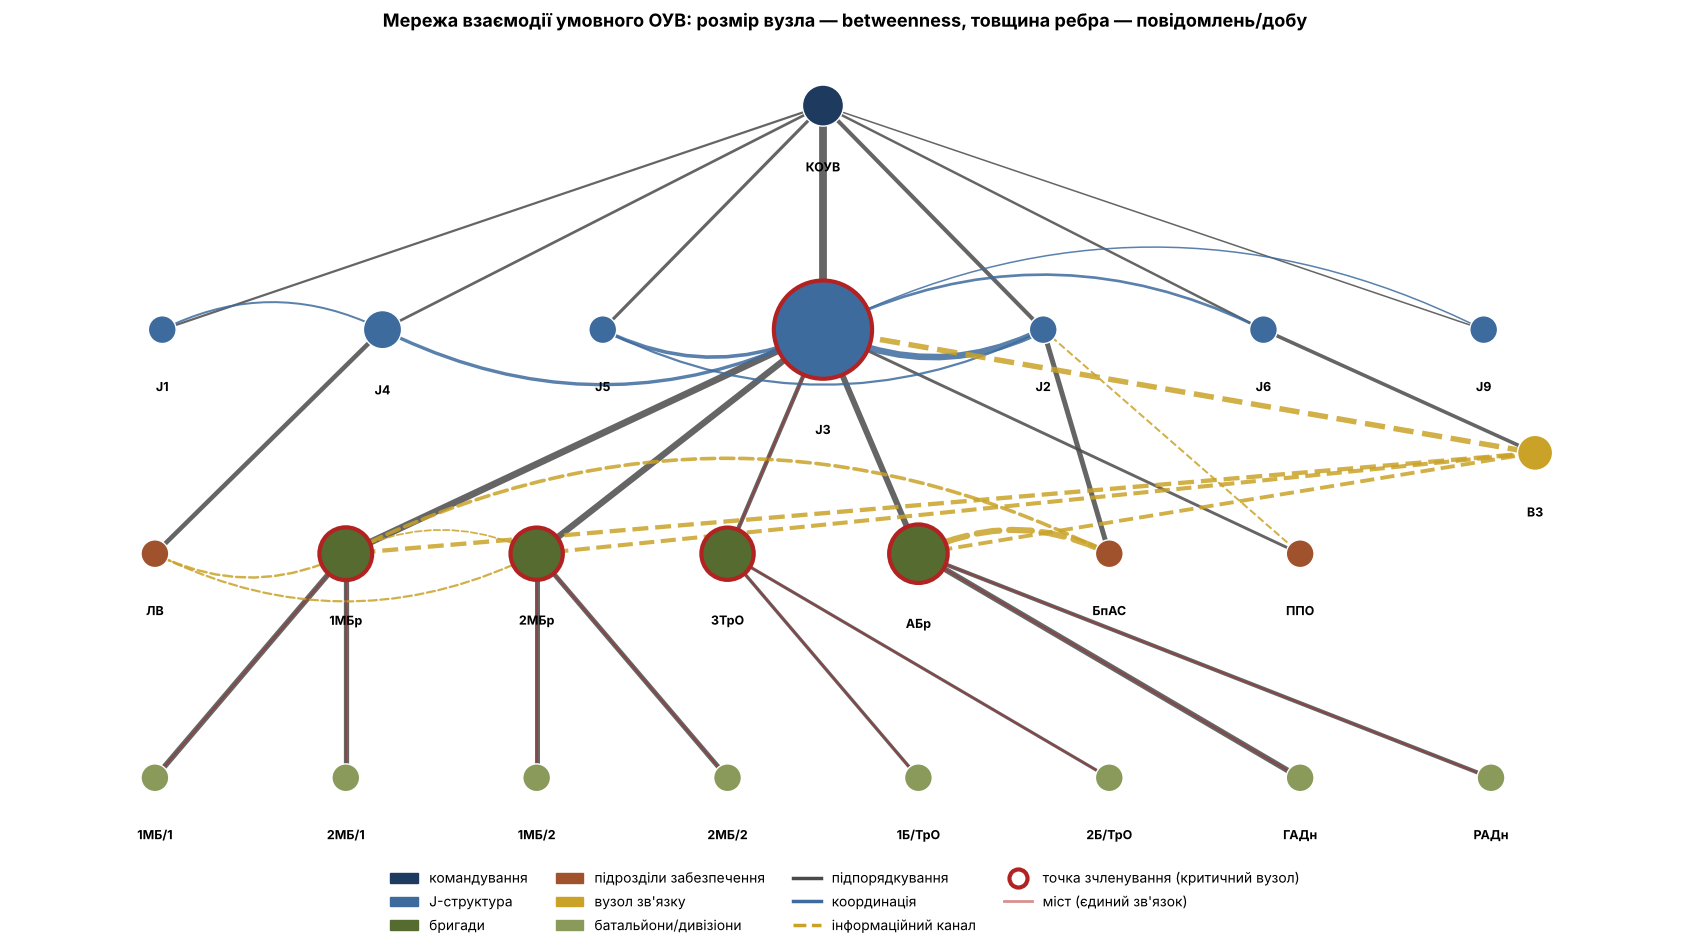

In [6]:
layers_y = {"command": 4, "staff": 3, "comms": 2.3, "brigade": 2, "support": 2, "battalion": 1}
order = {"command": ["КОУВ"], "staff": ["J1", "J4", "J5", "J3", "J2", "J6", "J9"],
         "row2": ["ЛВ", "1МБр", "2МБр", "3ТрО", "АБр", "БпАС", "ППО", "ВЗ"],
         "battalion": ["1МБ/1", "2МБ/1", "1МБ/2", "2МБ/2", "1Б/ТрО", "2Б/ТрО", "ГАДн", "РАДн"]}
pos = {}
for key, y in [("command", 4), ("staff", 3), ("row2", 2), ("battalion", 1)]:
    ids = order[key]
    for i, n in enumerate(ids):
        pos[n] = ((i - (len(ids) - 1) / 2) * (1.3 if key != "staff" else 1.5), y)
pos["ВЗ"] = (pos["ВЗ"][0] + 0.3, 2.45)

articulation = set(nx.articulation_points(G))
bridges = {tuple(sorted(e)) for e in nx.bridges(G)}

def draw_network(ax, highlight=True):
    for t, col in EDGE.items():
        es = [(u, v) for u, v, d in G.edges(data=True) if d["type"] == t]
        same_row = [e for e in es if abs(pos[e[0]][1] - pos[e[1]][1]) < 0.01]   # горизонтальні — дугою,
        other = [e for e in es if e not in same_row]                              # щоб не перекривали вузли
        kw = dict(ax=ax, edge_color=col, alpha=0.85, style="solid" if t != "інформаційний канал" else "dashed")
        nx.draw_networkx_edges(G, pos, edgelist=other, width=[0.6 + G[u][v]["weight"] / 6 for u, v in other], **kw)
        if same_row:
            nx.draw_networkx_edges(G, pos, edgelist=same_row, width=[0.6 + G[u][v]["weight"] / 6 for u, v in same_row],
                                   arrows=True, arrowstyle="-", connectionstyle="arc3,rad=-0.25",
                                   node_size=[400 + 6000 * btw[n] for n in G], **kw)
    if highlight:
        nx.draw_networkx_edges(G, pos, edgelist=list(bridges), ax=ax, edge_color="#B22222", width=1.2, alpha=0.5)
    sizes = [400 + 6000 * btw[n] for n in G]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=sizes, node_color=[PAL[G.nodes[n]["level"]] for n in G],
                           edgecolors=["#B22222" if (n in articulation and highlight) else "white" for n in G],
                           linewidths=[3 if (n in articulation and highlight) else 1 for n in G])
    for n, (x, y) in pos.items():
        ax.text(x, y - 0.22 - 0.25 * btw[n], n, ha="center", va="top", fontsize=9, weight="bold")
    ax.axis("off")

fig, ax = plt.subplots(figsize=(17, 9.5))
draw_network(ax)
legend = [mpatches.Patch(color=c, label=l) for l, c in
          [("командування", PAL["command"]), ("J-структура", PAL["staff"]), ("бригади", PAL["brigade"]),
           ("підрозділи забезпечення", PAL["support"]), ("вузол зв'язку", PAL["comms"]), ("батальйони/дивізіони", PAL["battalion"])]]
legend += [Line2D([0], [0], color=c, lw=2.5, ls="--" if t == "інформаційний канал" else "-", label=t) for t, c in EDGE.items()]
legend += [Line2D([0], [0], marker="o", color="w", markeredgecolor="#B22222", markeredgewidth=3, markersize=13,
                  label="точка зчленування (критичний вузол)"),
           Line2D([0], [0], color="#B22222", lw=2, alpha=0.5, label="міст (єдиний зв'язок)")]
ax.legend(handles=legend, loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
ax.set_title("Мережа взаємодії умовного ОУВ: розмір вузла — betweenness, товщина ребра — повідомлень/добу", fontsize=13)
plt.tight_layout(); plt.savefig("network_graph.png", dpi=150, bbox_inches="tight"); plt.show()

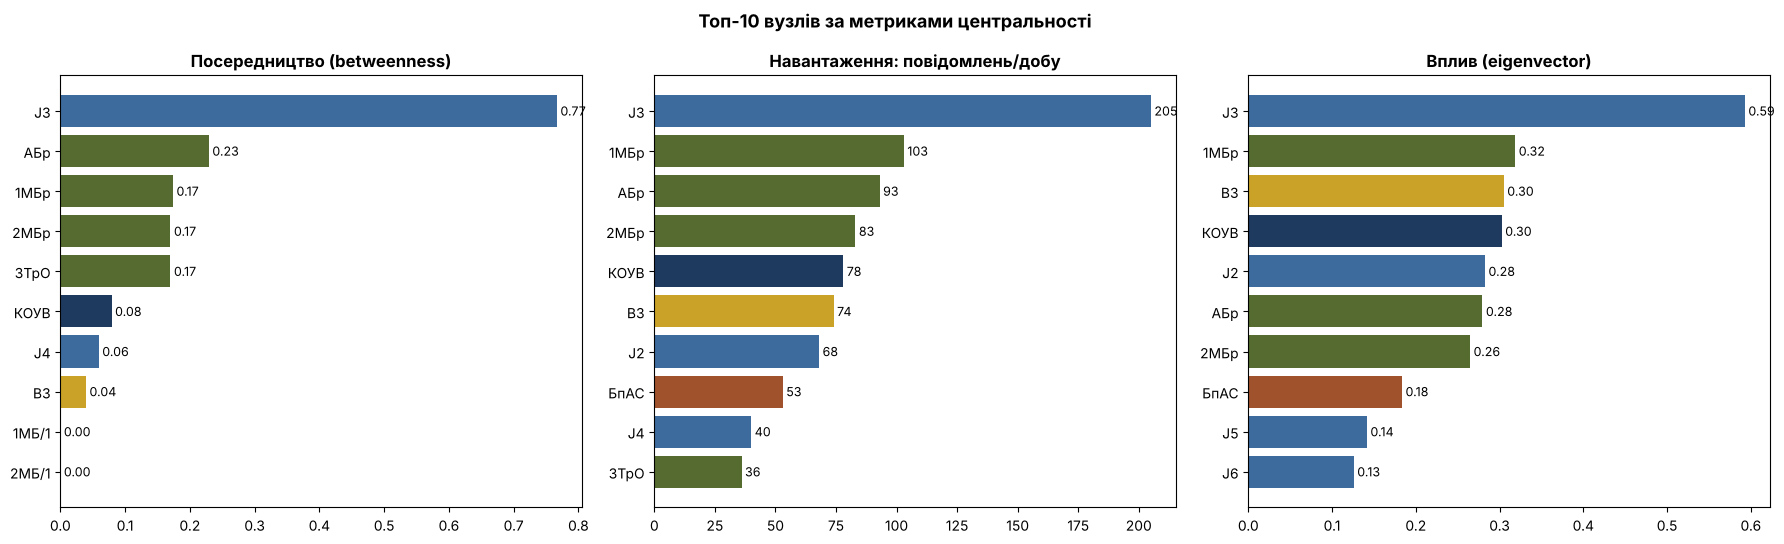

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, col, title in zip(axes, ["betweenness", "повідомл./добу", "eigenvector"],
                          ["Посередництво (betweenness)", "Навантаження: повідомлень/добу", "Вплив (eigenvector)"]):
    s = cent[col].sort_values().tail(10)
    ax.barh(s.index, s.values, color=[PAL[cent.loc[i, "level"]] for i in s.index])
    ax.set_title(title)
    for y, v in enumerate(s.values):
        ax.text(v, y, f" {v:.2f}" if v < 5 else f" {v:.0f}", va="center", fontsize=9)
plt.suptitle("Топ-10 вузлів за метриками центральності", fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

### 4.3. Слабкі місця: точки зчленування, мости, сценарії відмови
- **Точка зчленування** — вузол, вихід якого з ладу розбиває мережу на ізольовані частини.
- **Міст** — ребро, яке є єдиним шляхом між частинами мережі.
- **Стрес-тест:** по черзі «вимикаємо» кожен вузол і вимірюємо падіння **глобальної ефективності** мережі (середнє 1/довжина шляху між усіма парами) і кількість відрізаних вузлів.

In [8]:
print("Точки зчленування:", sorted(articulation))
print("Мости:", sorted(bridges))

E0 = nx.global_efficiency(G)
rows = []
for n in G:
    H = G.copy(); H.remove_node(n)
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    rows.append({"вузол": n, "падіння ефективності, %": 100 * (1 - nx.global_efficiency(H) / E0),
                 "відрізано вузлів": len(H) - len(comps[0]), "частин мережі": len(comps)})
stress = pd.DataFrame(rows).sort_values("падіння ефективності, %", ascending=False).set_index("вузол")
stress.head(8).round(1)

Точки зчленування: ['1МБр', '2МБр', '3ТрО', 'J3', 'АБр']
Мости: [('1Б/ТрО', '3ТрО'), ('1МБ/1', '1МБр'), ('1МБ/2', '2МБр'), ('1МБр', '2МБ/1'), ('2Б/ТрО', '3ТрО'), ('2МБ/2', '2МБр'), ('3ТрО', 'J3'), ('АБр', 'ГАДн'), ('АБр', 'РАДн')]


,"падіння ефективності, %",відрізано вузлів,частин мережі
вузол,,,
J3,28.2,3,2
1МБр,15.7,2,3
2МБр,14.5,2,3
АБр,13.0,2,3
3ТрО,11.4,2,3
КОУВ,2.8,0,1
ВЗ,2.0,0,1
J2,1.7,0,1


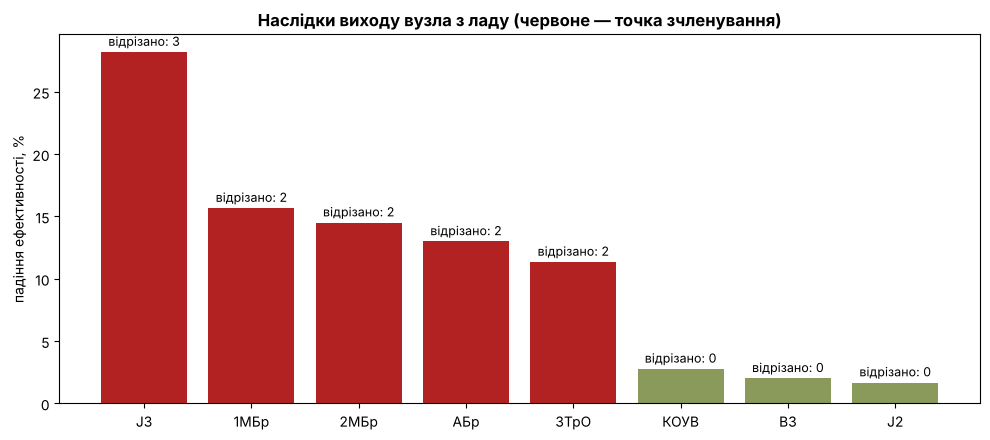

In [9]:
top = stress.head(8)
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(top.index, top["падіння ефективності, %"],
              color=["#B22222" if n in articulation else "#8A9A5B" for n in top.index])
for b, cut in zip(bars, top["відрізано вузлів"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f"відрізано: {cut}", ha="center", fontsize=9)
ax.set_ylabel("падіння ефективності, %")
ax.set_title("Наслідки виходу вузла з ладу (червоне — точка зчленування)")
plt.tight_layout(); plt.show()

### 4.4. Сценарій посилення: дублювання каналів
Перевіримо, як зміниться стійкість, якщо додати 4 резервні канали (через опорний вузол зв'язку та пряму горизонтальну взаємодію).

In [10]:
proposed = [("ВЗ", "3ТрО", "інформаційний канал", 8), ("ВЗ", "БпАС", "інформаційний канал", 8),
            ("КОУВ", "ВЗ", "інформаційний канал", 6), ("АБр", "2МБр", "інформаційний канал", 6)]
G2 = G.copy()
for u, v, t, w in proposed:
    G2.add_edge(u, v, type=t, weight=w, distance=1 / w)

def resilience(Gx):
    E = nx.global_efficiency(Gx)
    worst = max(1 - nx.global_efficiency(nx.restricted_view(Gx, [n], [])) / E for n in Gx)
    return {"точок зчленування": len(list(nx.articulation_points(Gx))), "мостів": len(list(nx.bridges(Gx))),
            "глобальна ефективність": E, "найгірше падіння, %": 100 * worst,
            "betweenness J3": nx.betweenness_centrality(Gx, weight="distance")["J3"]}

pd.DataFrame({"поточна мережа": resilience(G), "+4 резервні канали": resilience(G2)}).round(3)

,поточна мережа,+4 резервні канали
точок зчленування,5.000,4.000
мостів,9.000,8.000
глобальна ефективність,0.480,0.496
"найгірше падіння, %",28.192,15.225
betweenness J3,0.767,0.767


### 4.5. Інтерактивна версія (Plotly)
Зберігається у файл `network_interactive.html`; при наведенні на вузол — назва, кількість зв'язків, навантаження та betweenness.

In [11]:
import plotly.graph_objects as go
traces = []
for t, col in EDGE.items():
    xs, ys = [], []
    for u, v, d in G.edges(data=True):
        if d["type"] == t:
            xs += [pos[u][0], pos[v][0], None]; ys += [pos[u][1], pos[v][1], None]
    traces.append(go.Scatter(x=xs, y=ys, mode="lines", line=dict(color=col, width=1.6), name=t, hoverinfo="skip"))
traces.append(go.Scatter(
    x=[pos[n][0] for n in G], y=[pos[n][1] for n in G], mode="markers+text", text=list(G),
    textposition="bottom center", name="вузли",
    marker=dict(size=[14 + 70 * btw[n] for n in G], color=[PAL[G.nodes[n]["level"]] for n in G],
                line=dict(color=["#B22222" if n in articulation else "white" for n in G], width=2)),
    hovertext=[f"<b>{G.nodes[n]['name']}</b><br>зв'язків: {G.degree(n)}<br>повідомл./добу: {strength[n]}"
               f"<br>betweenness: {btw[n]:.3f}{'<br><b>точка зчленування</b>' if n in articulation else ''}" for n in G],
    hoverinfo="text"))
fig = go.Figure(traces)
fig.update_layout(title="Мережа взаємодії ОУВ (інтерактивна)", plot_bgcolor="white", height=650,
                  xaxis=dict(visible=False), yaxis=dict(visible=False), legend=dict(orientation="h"))
fig.write_html("network_interactive.html", include_plotlyjs="cdn")
print("Збережено network_interactive.html")

Збережено network_interactive.html


## 5. Аналітичні висновки

In [12]:
top3 = cent.head(3)
print("Найвищий betweenness:", ", ".join(f"{i} ({v:.2f})" for i, v in top3["betweenness"].items()))
print("Найбільше навантаження:", ", ".join(f"{i} ({v})" for i, v in cent["повідомл./добу"].nlargest(3).items()))
print("Точки зчленування:", ", ".join(sorted(articulation)), "| мостів:", len(bridges))
print("Найкритичніший вузол за стрес-тестом:", stress.index[0],
      f"(−{stress.iloc[0]['падіння ефективності, %']:.1f}% ефективності, відрізано {stress.iloc[0]['відрізано вузлів']})")

Найвищий betweenness: J3 (0.77), АБр (0.23), 1МБр (0.17)
Найбільше навантаження: J3 (205), 1МБр (103), АБр (93)
Точки зчленування: 1МБр, 2МБр, 3ТрО, J3, АБр | мостів: 9
Найкритичніший вузол за стрес-тестом: J3 (−28.2% ефективності, відрізано 3.0)


1. **Центральний вузол — J3 (ЦУО).** 12 зв'язків, найбільше навантаження (205 повідомлень/добу, удвічі більше, ніж у наступного вузла) і betweenness 0.77: через J3 проходять понад три чверті найкоротших шляхів у мережі. Для оперативного управління це очікувано, але J3 — **«вузьке горло»**: його перевантаження або втрата одразу зупиняє цикл управління.
2. **Критичні вузли (точки зчленування): J3, 1МБр, 2МБр, АБр, 3ТрО.** Найнебезпечніший сценарій — втрата J3: мережа розпадається на 2 частини (відрізано 3ТрО з батальйонами), глобальна ефективність падає на 28%. Втрата будь-якої бригади відрізає її батальйони (−11…−16%).
3. **Слабкі місця інформаційних потоків — 9 мостів.** Кожен батальйон/дивізіон має **єдиний** канал зі своєю бригадою, а 3ТрО — єдиний канал зі штабом (через J3): у неї немає ні горизонтальних зв'язків із сусідами, ні каналу через опорний вузол зв'язку.
4. **Командувач, J2, J6 та опорний вузол зв'язку не є точками зчленування:** їх втрата знижує ефективність лише на 2–3%, оскільки існують обхідні шляхи. Найінтенсивніший горизонтальний канал — **БпАС → АБр** (23 повідомлення/добу): цілевказування йде напряму, минаючи штаб, що скорочує цикл «виявлення — ураження».
5. **Опорний вузол зв'язку** дублює зв'язок J3 з 1МБр, 2МБр і АБр, тож ці бригади зберігають зв'язок зі штабом навіть через альтернативний маршрут; 3ТрО такого резерву не має.

## 6. Рекомендації для штабу
- **Задублювати канали 3ТрО та БпАС** через опорний вузол зв'язку, додати резервний канал КОУВ ↔ ВЗ і горизонтальний АБр ↔ 2МБр. Сценарій 4.4 показує: найгірше падіння ефективності при втраті одного вузла зменшується з 28% до 15%, J3 перестає бути точкою зчленування для 3ТрО (точок зчленування 5 → 4, мостів 9 → 8).
- **Батальйонний рівень** лишається з мостами — потрібні резервні канали батальйон ↔ сусідній батальйон / вузол зв'язку (радіо + супутниковий/mesh зв'язок).
- **Розвантажити J3:** betweenness J3 після додавання резервних каналів не змінився (0.77) — резерв лише страхує, а основний обмін і далі йде через J3. Рутинний обмін (логістика, донесення про стан) варто перевести на прямі канали J4 ↔ бригади та автоматизовану систему ситуаційної обізнаності.
- **Підготувати заступний пункт управління** з функціями J3, щоб втрата одного вузла не розривала управління.
- **Регулярно оновлювати граф** за фактичними журналами обміну (кількість повідомлень, затримки) — тоді метрики відображатимуть реальні, а не планові потоки.

### Самоперевірка (контрольні запитання)
1. Тип візуалізації відповідає реляційним даним — ✔ мережевий граф + метрики.
2. Перевантаження немає: колір — рівень, розмір — посередництво, товщина — інтенсивність, червоне — вразливість.
3. За 5 секунд видно: J3 — найбільший вузол у центрі, червоні обведення — критичні вузли, червоні лінії — мости.
4. Ключові висновки сформульовано (5 пунктів) — ✔.
5. Вплив на рішення штабу — рекомендації щодо дублювання каналів і заступного пункту управління — ✔.